In [8]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/7/2022
# version ='1.0'

### Demo: solving the geometric program: \textit{Frobenius norm scaling}

In the text book {book-convex-2004}, section 9.4, 'Steepest descent method', Example 9.2, an example of \textit{Frobenius norm scaling} was solved using the steepest descent for $l_1$ norm. Here is a demo to verify the solution.

The geometric program in a convex form is

$$
\begin{array}{rccl}
minimize & f(x) & = & \log\left(\displaystyle{\sum_{i,j=1}^{n}M_{i,j}^2 e^{x_i-x_j}}  \right) 
\end{array}
$$

The advantage of the $l_1$-steepest descent algorithm (also called \textit{coordinate-descent}) is, the exact line search can be carried out using a simple analytical formula.

In the demo, the coefficient matrix $M$ is randomly generated. If $n=2$, then the minimum of $f(x)$ is attained along a line satisfying $\nabla f(x)=0$, i.e.

$$
\{x = (x_1, x_2) \vert x_2 = x_1 - \log(M_{2,1}/M_{1,2})\}
$$

For $n=10, 20, 30, 40, 50$, each starting from $x_o=0$, and the coordinate-descent algorithm exits when the norm of the gradient is less than $\epsilon$=1e-5.

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).


In [9]:
import numpy as np
import math
import matplotlib.pyplot as plt

$f(x)  =  \log\displaystyle{\sum_{i,j=1}^{n}M_{i,j}^2 e^{x_i-x_j}}$

$\nabla f(x)$ should be calculated according to the derivations in Example 9.2 in section 9.4.1.



In [10]:
def my_f(x, M):
    """
    $$ f(x)  =  \log\left(\displaystyle{\sum_{i,j=1}^{n}M_{i,j}^2 e^{x_i-x_j}}  $$
    :param x:
    :param M:
    :return:
    """
    n = len(x)
    s = 0
    Exixj = np.exp(x - x.T)
    M_E = (M ** 2) * Exixj
    sum_M_E = np.sum(M_E)
    return np.log(sum_M_E)


def my_gradient_f(x, M):
    """
    Calculate $\nabla f(x)$ according to the derivations in Example 9.2 in section 9.4.1
    :param x:
    :param M:
    :return:
    """
    n = len(x)
    alpha = np.zeros((n, 1))
    beta = np.zeros((n, 1))
    gamma = np.zeros((n, 1))
    for k in range(n):
        alpha[k] = M[k][k] ** 2
        beta[k] = 0.
        gamma[k] = 0.
        for i in range(n):
            for j in range(n):
                if (i != k) and (j != k):
                    alpha[k] += (M[i][j] ** 2) * math.exp(x[i] - x[j])

        for i in range(n):
            if (i != k):
                beta[k] += (M[i][k] ** 2) * math.exp(x[i])

        for j in range(n):
            if (j != k):
                gamma[k] += (M[k][j] ** 2) * math.exp(-x[j])

    gradient = np.zeros((n, 1))
    for i in range(n):
        exp_m_xi = math.exp(-x[i])
        exp_p_xi = math.exp(+x[i])
        gradient[i] = (-beta[i] * exp_m_xi + gamma[i] * exp_p_xi) / (
                alpha[i] + beta[i] * exp_m_xi + gamma[i] * exp_p_xi)

    return gradient, alpha, beta, gamma

Plot the convergence of steepest descent method when applied to Frobenius norm scaling method, when n=2

In [11]:
def plot_steepest_descent_convergence_Frobenius_norm_scaling_n2(ax):
    """
    plot the convergence of steepest descent method when applied to Frobenius norm scaling method, when n=2
    :param ax:
    :return:
    """
    n = 2
    np.random.seed(1)
    M = np.random.rand(n, n)

    min_x1 = -18
    max_x1 = 2
    min_x2 = -10
    max_x2 = 10
    delta = 0.05
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([[x1], [x2]]), M)

    levels = np.arange(-1.5, -1, 0.001)
    # levels = np.arange(0, 10, 0.1)
    CS = ax.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=-2, vmax=0)

    offset = math.log(M[1, 0] / M[0, 1])
    ax.plot(x, [_x - offset for _x in x], linestyle='dashed', color='red', label=r'$x_2$ = $x_1$ - $\log$($M_{2,1}$/$M_{1,2}$)')
    ax.clabel(CS, fontsize=6, inline=True)

    x0 = -5 * np.ones((n, 1))
    x = x0
    epsilon = 1e-5
    x_s = [[x[0,0], x[1,0]]]
    while True:

        gradient, alpha, beta, gamma = my_gradient_f(x, M)
        gradient_abs = np.abs(gradient)
        k = np.argmax(gradient_abs)
        x_nsd = np.zeros((n, 1))
        x_nsd[k] = -1 * np.sign(gradient[k])
        old_xk = x[k]
        new_xk = 0.5 * np.log(beta[k] / gamma[k])
        t = (new_xk - old_xk) / x_nsd[k]
        if t < 0:
            raise RuntimeError("t < 0 should not happen")
        x[k] = new_xk

        x_s.append([x[0,0], x[1,0]])

        if np.linalg.norm(gradient) < epsilon:
            break

    ax.plot([_x[0] for _x in x_s], [_x[1] for _x in x_s], linestyle='solid', marker='o', color='blue', fillstyle='none', label=r'$l_1$ steepest descent')

    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
    ax.set_title(r'$f(x)$')
    ax.set_xlim([min_x1, max_x1])
    ax.set_ylim([min_x2, max_x2])
    ax.grid()
    ax.legend()

Plot the convergence of steepest descent method when applied to Frobenius norm scaling method for different n

In [12]:
def plot_steepest_descent_convergence_Frobenius_norm_scaling_vs_n(n_s, ax):
    """
    plot the convergence of steepest descent method when applied to Frobenius norm scaling method for different n
    :param n_s:
    :param ax:
    :return:
    """
    for n in n_s:
        np.random.seed(1)
        print('Info: running simulation for n = {}'.format(n))
        M = np.random.rand(n, n)

        x0 = np.zeros((n, 1))
        x = x0
        epsilon = 1e-5
        f_s = [my_f(x, M)]

        while True:
            gradient, alpha, beta, gamma = my_gradient_f(x, M)
            gradient_abs = np.abs(gradient)
            k = np.argmax(gradient_abs)
            x_nsd = np.zeros((n, 1))
            x_nsd[k] = -1 * np.sign(gradient[k])
            old_xk = x[k]
            new_xk = 0.5 * np.log(beta[k] / gamma[k])
            t = (new_xk - old_xk) / x_nsd[k]
            if t < 0:
                raise RuntimeError("t < 0 should not happen")
            x[k] = new_xk

            f_s.append(my_f(x, M))
            #ax2.plot(np.arange(n), x, marker='x', linestyle='')

            if np.linalg.norm(gradient) < epsilon:
                break

        ax.semilogy(f_s-f_s[-1], marker='+', linestyle='dashed', label='n={}'.format(n))

        gradient, alpha, beta, gamma = my_gradient_f(x, M)
        xk_p = np.zeros((n, 1))
        for k in range(n):
            xk_p[k] = 0.5 * np.log(beta[k] / gamma[k])

    ax.set_xlabel(r'$iteration$')
    ax.set_ylabel(r'$f(x)-f(x^*)$')
    #ax.set_title(r'$convergence$')
    #ax.legend()
    ax.grid()

Info: running simulation for n = 10
Info: running simulation for n = 50


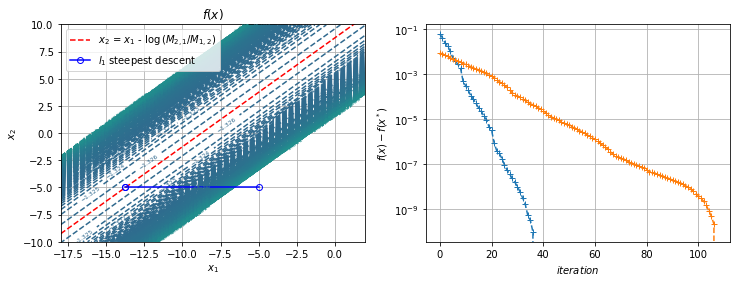

In [13]:
if __name__ == "__main__":
    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 2, 1)
    plot_steepest_descent_convergence_Frobenius_norm_scaling_n2(ax)

    n_s = [10, 50]
    ax = plt.subplot(1, 2, 2)
    plot_steepest_descent_convergence_Frobenius_norm_scaling_vs_n(n_s, ax)

    plt.show()